In [1]:
# 데이터 로드
from sklearn.datasets import fetch_openml
mnist=fetch_openml('mnist_784', version=1)

In [2]:
# train, test split
X_train = mnist['data'][:60000]
y_train = mnist['target'][:60000]
X_test = mnist['data'][60000:]
y_test = mnist['target'][60000:]

* 랜덤포레스트에 적용

In [3]:
# 랜덤포레스트에 적용 (n_estimators=10, random_state=42)
from sklearn.ensemble import RandomForestClassifier
import time

rnd_clf = RandomForestClassifier(n_estimators=10, random_state=42)
t0 = time.time()
rnd_clf.fit(X_train, y_train)
print(f"훈련 시간: {time.time() - t0:.2f}초")

훈련 시간: 15.30초


In [4]:
# 정확도 결과
from sklearn.metrics import accuracy_score

y_pred = rnd_clf.predict(X_test)
print("정확도:", accuracy_score(y_test, y_pred))

# 1. PCA

* PCA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [5]:
# PCA 라이브러리 불러오기
from sklearn.decomposition import PCA

In [6]:
# PCA 적용 95% : n_components=0.95
pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)
print("축소된 차원 수:", pca.n_components_)

축소된 차원 수: 154


In [7]:
# PCA 이후 랜덤포레스트 훈련
rnd_clf2 = RandomForestClassifier(n_estimators=10, random_state=42)
t0 = time.time()
rnd_clf2.fit(X_train_reduced, y_train)
print(f"훈련 시간: {time.time() - t0:.2f}초")

훈련 시간: 26.98초


In [8]:
# 정확도 결과 (X_test도 PCA 적용해야합니다.)
X_test_reduced = pca.transform(X_test)   # fit은 train에만, test는 transform만
y_pred = rnd_clf2.predict(X_test_reduced)
print("정확도:", accuracy_score(y_test, y_pred))

정확도: 0.8925


**관련 문제**

* PCA모델을 와인 데이터셋에 적용하여 차원을 축소하고 그 결과를 그래프로 나타내보세요.

(1) 필요한 모듈 불러오기

In [9]:
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

(2)  load_wine을 사용해 데이터셋을 생성한다.

In [10]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name='target')
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


(3) X에 표준 스케일링(Standard scaling)을 적용하여 X_scaled을 생성한다.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:3]

array([[ 1.51861254, -0.5622498 ,  0.23205254, -1.16959318,  1.91390522,
         0.80899739,  1.03481896, -0.65956311,  1.22488398,  0.25171685,
         0.36217728,  1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, -2.49084714,  0.01814502,
         0.56864766,  0.73362894, -0.82071924, -0.54472099, -0.29332133,
         0.40605066,  1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, -0.2687382 ,  0.08835836,
         0.80899739,  1.21553297, -0.49840699,  2.13596773,  0.26901965,
         0.31830389,  0.78858745,  1.39514818]])

(4) PCA 모델을 X에 적용하여 2개의 차원으로 추출한다. 단, random_state=1234로 설정한다.

In [12]:
#PCA 모델을 X_scaled에 적용하여 2개의 차원으로 추출한다.
pca_wine = PCA(n_components=2, random_state=1234)
X_pca = pca_wine.fit_transform(X_scaled)

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['target'] = y
print("설명된 분산 비율:", pca_wine.explained_variance_ratio_)
df_pca.head()

설명된 분산 비율: [0.36198848 0.1920749 ]


,PC1,PC2,target
0,3.316751,1.443463,0
1,2.209465,-0.333393,0
2,2.516740,1.031151,0
3,3.757066,2.756372,0
4,1.008908,0.869831,0


(5) 추출한 피처를 그래프로 나타내라.

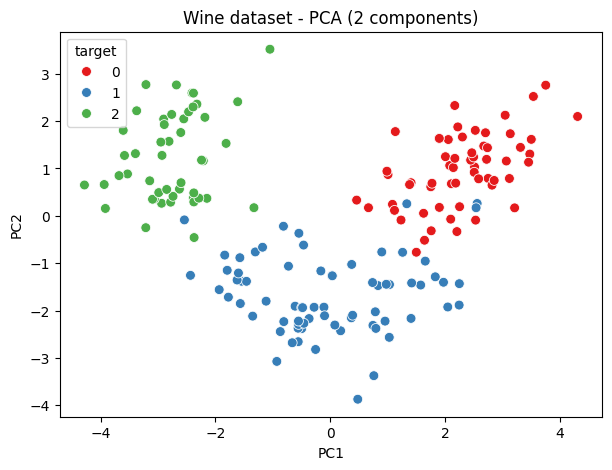

In [13]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='target', palette='Set1', s=50)
plt.title('Wine dataset - PCA (2 components)')
plt.show()

# 2. LDA

- LDA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [14]:
# LDA 라이브러리 불러오기
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [15]:
# LDA 적용 : n_components=5
lda = LinearDiscriminantAnalysis(n_components=5)
X_train_lda = lda.fit_transform(X_train, y_train)
print(X_train_lda.shape)

# (LDA의 최대 차원 = 클래스 수 - 1 = 9, 지도학습이므로 y_train 필요)

(60000, 5)


In [16]:
# LDA 이후 랜덤포레스트 훈련
rnd_clf3 = RandomForestClassifier(n_estimators=10, random_state=42)
t0 = time.time()
rnd_clf3.fit(X_train_lda, y_train)
print(f"훈련 시간: {time.time() - t0:.2f}초")

훈련 시간: 2.98초


In [17]:
# 정확도 결과 (X_test도 LDA 적용해야합니다.)
X_test_lda = lda.transform(X_test)
y_pred = rnd_clf3.predict(X_test_lda)
print("정확도:", accuracy_score(y_test, y_pred))

정확도: 0.8301
